<a href="https://colab.research.google.com/github/GautamPandit2405/Project-Versility/blob/main/online_retail_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
df = pd.read_excel("/content/Online Retail.xlsx")
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
df.head()

Dataset loaded successfully!
Number of rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
#1. check the dataset size
print("Dataset shape:", df.shape)
#2. Check column names and data types
df.info()
#3. Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())
#4 Display basic statistics
df.describe()

Dataset shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [3]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


In [4]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [5]:

# Keep the original dataset unchanged
clean_df = df.copy()

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# Remove rows without essential sales information
clean_df = clean_df.dropna(
    subset=["InvoiceNo", "Quantity", "UnitPrice", "InvoiceDate"]
)

# Keep positive quantities and non-negative unit prices
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] >= 0)
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Remaining missing values:")
print(clean_df.isnull().sum())


Original rows: 541909
Cleaned rows: 526052
Remaining missing values:
InvoiceNo           0
StockCode           0
Description       592
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133320
Country             0
dtype: int64


In [6]:

# Calculate revenue for each transaction
clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

print("Total Revenue:", round(clean_df["Revenue"].sum(), 2))
print("Total Transactions:", clean_df["InvoiceNo"].nunique())

clean_df.head()


Total Revenue: 10642110.8
Total Transactions: 20726


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [7]:

top_products = (
    clean_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


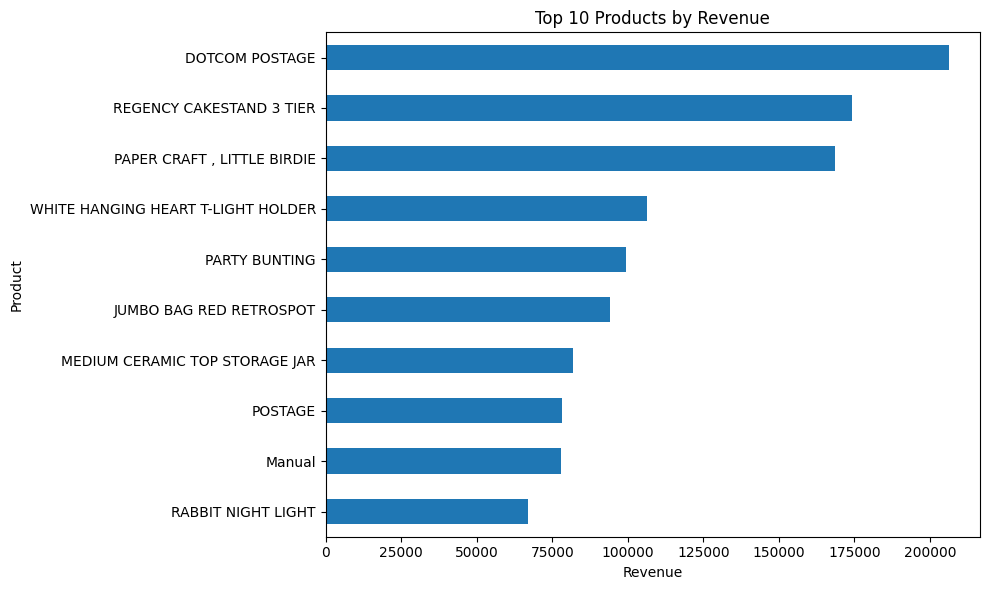

In [8]:

import matplotlib.pyplot as plt

top_products.sort_values().plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [9]:

clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])

clean_df["Month"] = clean_df["InvoiceDate"].dt.to_period("M")

print(clean_df[["InvoiceDate", "Month", "Revenue"]].head())


          InvoiceDate    Month  Revenue
0 2010-12-01 08:26:00  2010-12    15.30
1 2010-12-01 08:26:00  2010-12    20.34
2 2010-12-01 08:26:00  2010-12    22.00
3 2010-12-01 08:26:00  2010-12    20.34
4 2010-12-01 08:26:00  2010-12    20.34


In [10]:

monthly_sales = (
    clean_df.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

print(monthly_sales)


Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


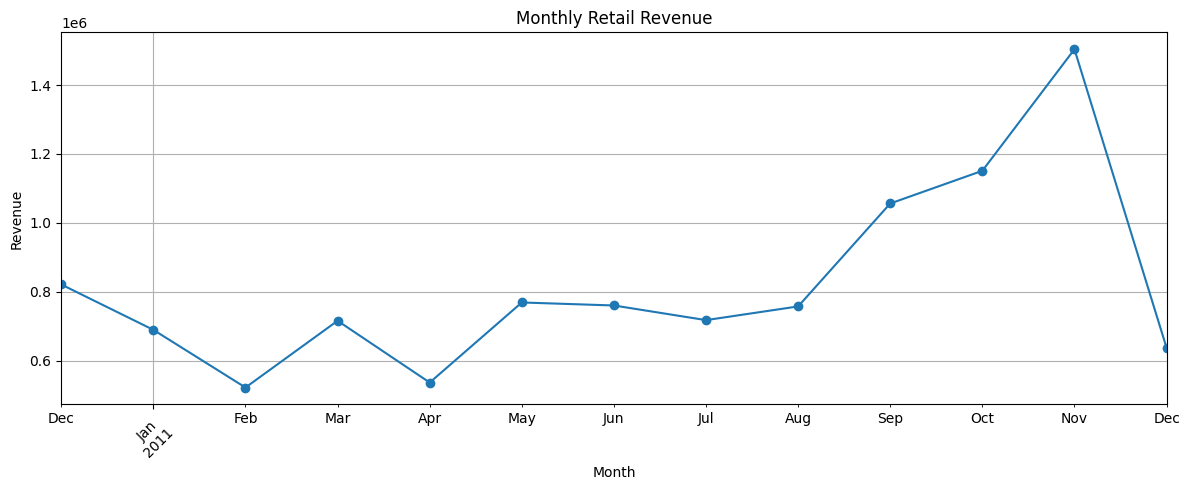

In [11]:

monthly_sales.plot(figsize=(12, 5), marker="o")

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [12]:

best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

print("Highest revenue month:", best_month)
print("Revenue:", round(best_month_revenue, 2))


Highest revenue month: 2011-11
Revenue: 1503866.78


In [13]:

# 1. Highest-revenue product
best_product = top_products.index[0]
product_revenue = top_products.iloc[0]

# 2. Highest-revenue month
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

# 3. Lowest-revenue month
lowest_month = monthly_sales.idxmin()
lowest_month_revenue = monthly_sales.min()

print("Finding 1: Top product")
print(best_product, "-", round(product_revenue, 2))

print("\nFinding 2: Highest revenue month")
print(best_month, "-", round(best_month_revenue, 2))

print("\nFinding 3: Lowest revenue month")
print(lowest_month, "-", round(lowest_month_revenue, 2))


Finding 1: Top product
DOTCOM POSTAGE - 206248.77

Finding 2: Highest revenue month
2011-11 - 1503866.78

Finding 3: Lowest revenue month
2011-02 - 522545.56


## Key Findings — Online Retail Data Analysis

1. **Top-performing product:** [Product name] generated the highest recorded revenue among the top 10 products, with revenue of [amount].

2. **Strongest sales month:** [Month] recorded the highest monthly revenue of [amount], indicating a period of relatively strong sales in the analysed dataset.

3. **Lowest sales month:** [Month] recorded the lowest monthly revenue of [amount]. Further investigation is needed to determine whether this reflects seasonality, incomplete data, or other factors.

### Business Recommendation
The business should investigate the factors behind high-performing products and monthly sales fluctuations before making inventory or marketing decisions.